# 02 - Data Cleaning dan EDA (FR-02)
**Input:** `data/raw/bank-full.csv` · **Output:** `data/processed/bank_campaign_clean.csv`

- [x] Validasi skema, tipe data, missing value, dan duplikat
- [x] Pertahankan `unknown` sebagai kategori dan `pdays = -1` sebagai sentinel belum pernah dihubungi
- [x] Catat jumlah baris sebelum dan sesudah cleaning
- [x] Tampilkan distribusi target serta fitur numerik dan kategorikal
- [x] Bandingkan fitur terhadap `y` dan rangkum response rate per segmen
- [x] Simpan dataset bersih untuk Modul 3

In [1]:
# --- Setup path (jalan di VS Code / Jupyter. Untuk Colab, lihat sel opsional di bawah) ---
from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_PATH = ROOT / "data" / "raw" / "bank-full.csv"
CLEAN_PATH = ROOT / "data" / "processed" / "bank_campaign_clean.csv"
MODELS_DIR = ROOT / "models"
SQL_DIR = ROOT / "sql"
DASHBOARD_PATH = ROOT / "reports" / "bank_campaign_dashboard.xlsx"
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# (Opsional) Hanya jika dijalankan di Google Colab:
# from google.colab import drive
# drive.mount('/content/drive')
# import os; os.chdir('/content/drive/MyDrive/bank-campaign-response-analytics')  # sesuaikan lokasi folder
# Jalankan sel Setup di atas SETELAH baris ini.

In [3]:
df = pd.read_csv(RAW_PATH, sep=";")
df.columns = [c.strip().lower() for c in df.columns]
rows_before = len(df)
rows_before

45211

## Cleaning

- Baris duplikat identik dihapus agar satu observasi tidak dihitung berulang; tidak ditemukan duplikat pada data ini.
- Kolom numerik dikonversi dengan `to_numeric(errors="raise")`, sedangkan kolom teks dibersihkan dari spasi dan diseragamkan ke huruf kecil.
- Baris tanpa target tidak dapat dipakai untuk supervised learning, sehingga dibuang; target selain `yes`/`no` menyebabkan validasi gagal.
- Nilai kategori `unknown` dipertahankan karena merepresentasikan informasi yang tidak tercatat, bukan kategori yang boleh diasumsikan.
- `pdays = -1` dipertahankan sebagai penanda nasabah belum pernah dihubungi pada kampanye sebelumnya.
- Missing kategori diisi `unknown`; missing numerik dibiarkan agar dapat ditangani imputasi median pada pipeline Modul 3. Pada file ini tidak ditemukan missing.

In [4]:
import sys
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data_processing import (
    clean, EXPECTED_COLUMNS, NUMERIC_COLUMNS, CATEGORICAL_COLUMNS,
)

if df.columns.tolist() != EXPECTED_COLUMNS:
    raise ValueError("Skema kolom data mentah tidak sesuai dengan skema proyek.")

rows_before = len(df)
duplicate_rows = int(df.assign(**{
    column: df[column].astype("string").str.strip().str.lower()
    for column in CATEGORICAL_COLUMNS + ["y"]
}).duplicated().sum())
missing_target_rows = int(df["y"].isna().sum())
df_clean = clean(df)
rows_after = len(df_clean)
missing_after = df_clean.isna().sum().sort_values(ascending=False)
unknown_counts = df_clean[CATEGORICAL_COLUMNS].eq("unknown").sum().sort_values(ascending=False)
pdays_not_contacted = int(df_clean["pdays"].eq(-1).sum())

print(f"Baris: {rows_before:,} -> {rows_after:,}")
print(f"Duplikat exact dihapus: {duplicate_rows:,}")
print(f"Baris tanpa target: {missing_target_rows:,}")
print(f"Missing tersisa: {int(missing_after.sum()):,}")
print(f"Nilai pdays = -1 dipertahankan: {pdays_not_contacted:,}")
print("Jumlah kategori 'unknown' per kolom:")
display(unknown_counts[unknown_counts.gt(0)].to_frame("count"))

Baris: 45,211 -> 45,211
Duplikat dihapus : 0
Baris tanpa target dihapus: 0
Missing tersisa  : 0
pdays = -1       : 36,954
Unknown per kolom: {'job': 288, 'education': 1857, 'contact': 13020, 'poutcome': 36959}
Baris: 45,211 -> 45,211
Duplikat exact dihapus: 0
Baris tanpa target: 0
Missing tersisa: 0
Nilai pdays = -1 dipertahankan: 36,954
Jumlah kategori 'unknown' per kolom:


,count
poutcome,36959
contact,13020
education,1857
job,288


## EDA
_Distribusi target, fitur numerik/kategorikal, hubungan fitur vs `y`._

Response rate keseluruhan: 11.70%


,contacts,share_pct
y,,
no,39922,88.3
yes,5289,11.7


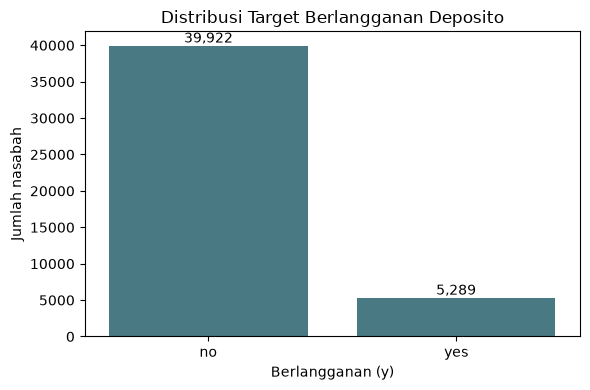

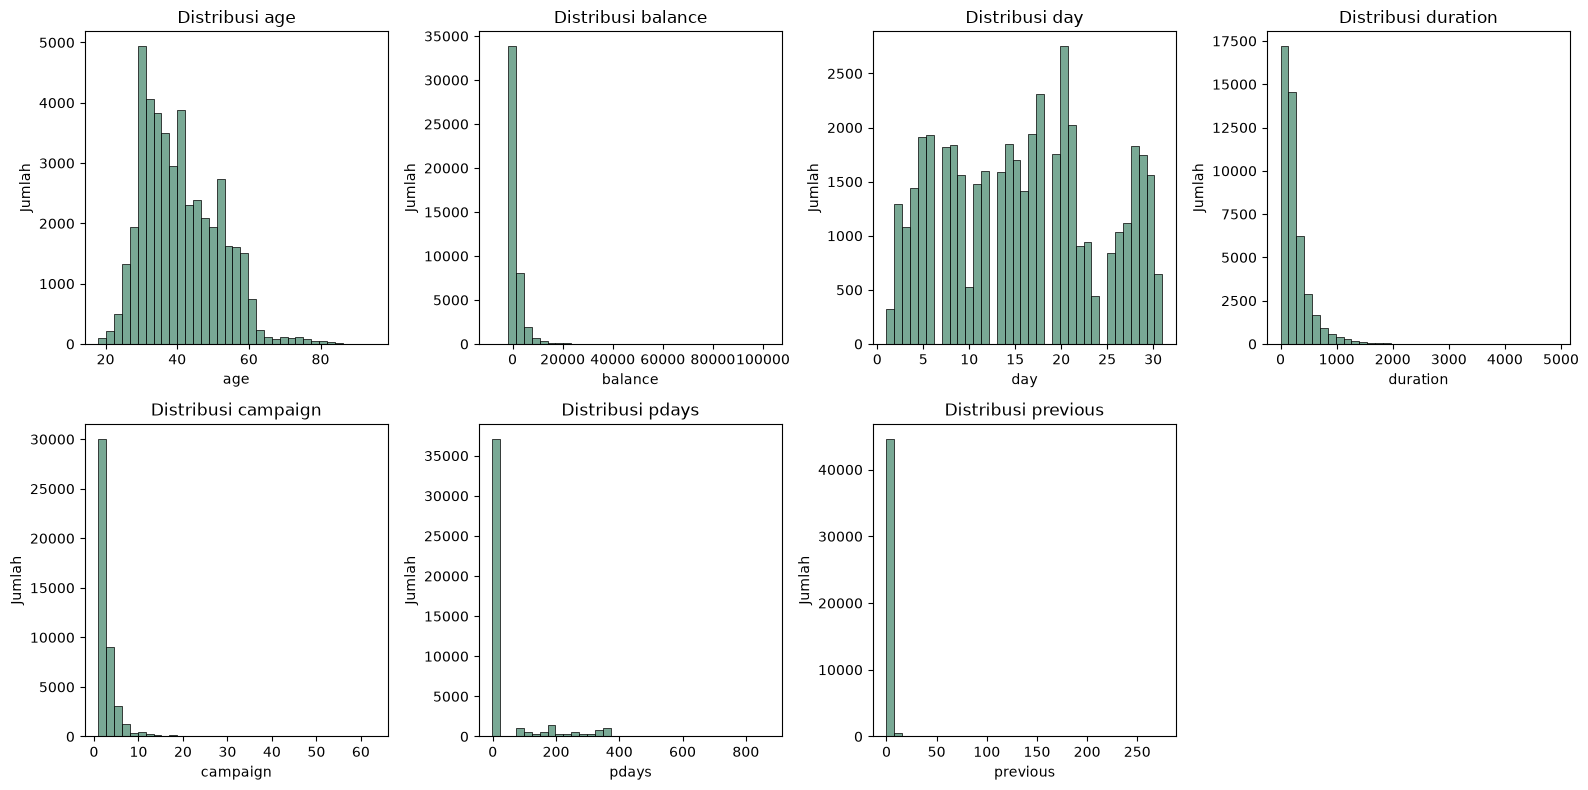

Ringkasan fitur numerik per target:


y                     no      yes
age      median    39.00    38.00
         mean      40.84    41.67
balance  median   417.00   733.00
         mean    1303.71  1804.27
day      median    16.00    15.00
         mean      15.89    15.16
duration median   164.00   426.00
         mean     221.18   537.29
campaign median     2.00     2.00
         mean       2.85     2.14
pdays    median    -1.00    -1.00
         mean      36.42    68.70
previous median     0.00     0.00
         mean       0.50     1.17

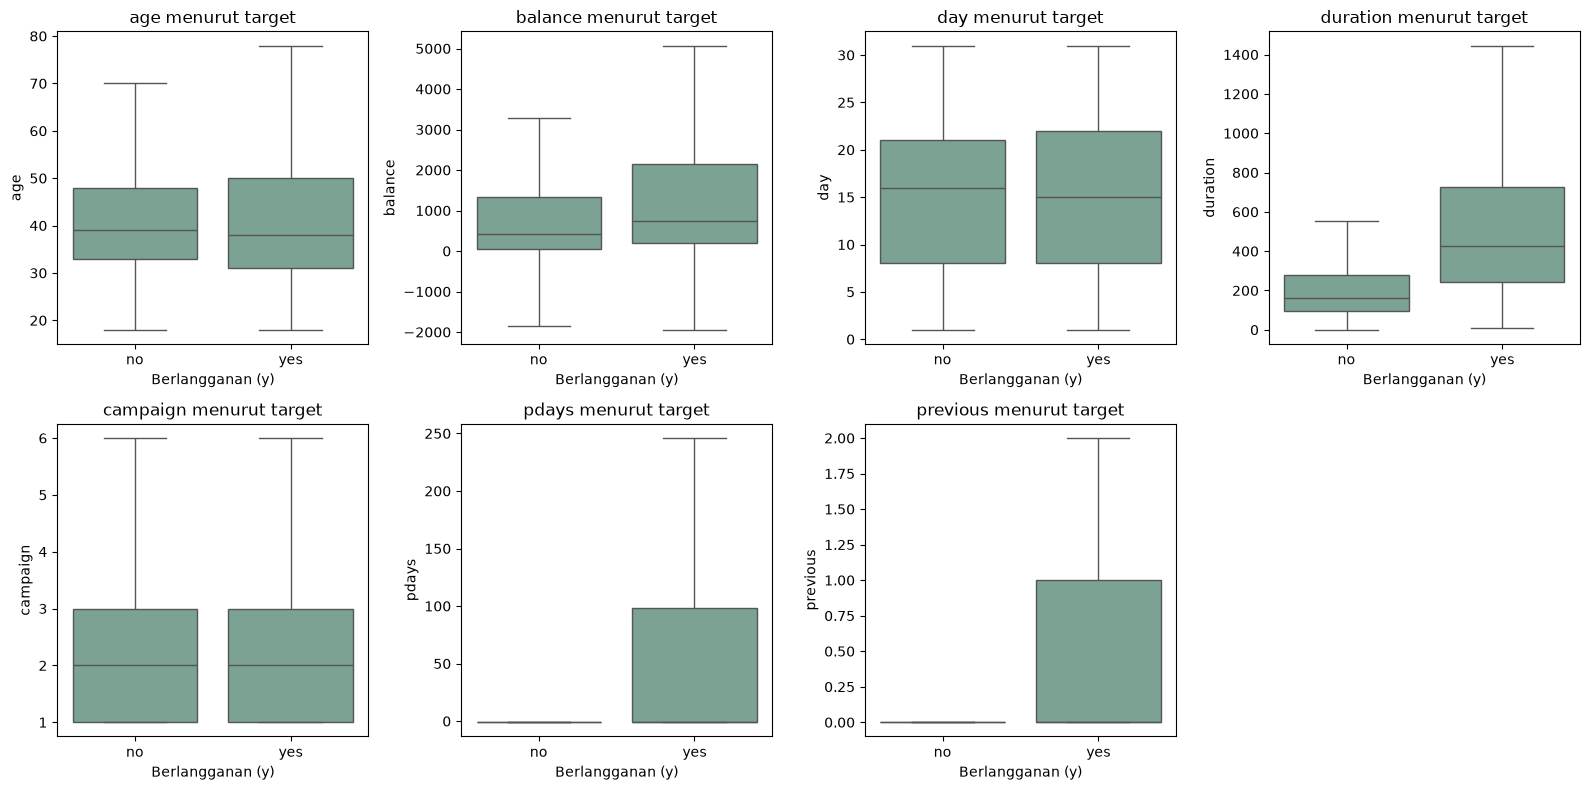

,feature,segment,contacts,subscriptions,response_rate_pct
0,contact,cellular,29285,4369,14.92
1,contact,telephone,2906,390,13.42
2,contact,unknown,13020,530,4.07
3,default,no,44396,5237,11.80
4,default,yes,815,52,6.38
5,education,tertiary,13301,1996,15.01
6,education,unknown,1857,252,13.57
7,education,secondary,23202,2450,10.56
8,education,primary,6851,591,8.63
9,housing,no,20081,3354,16.70


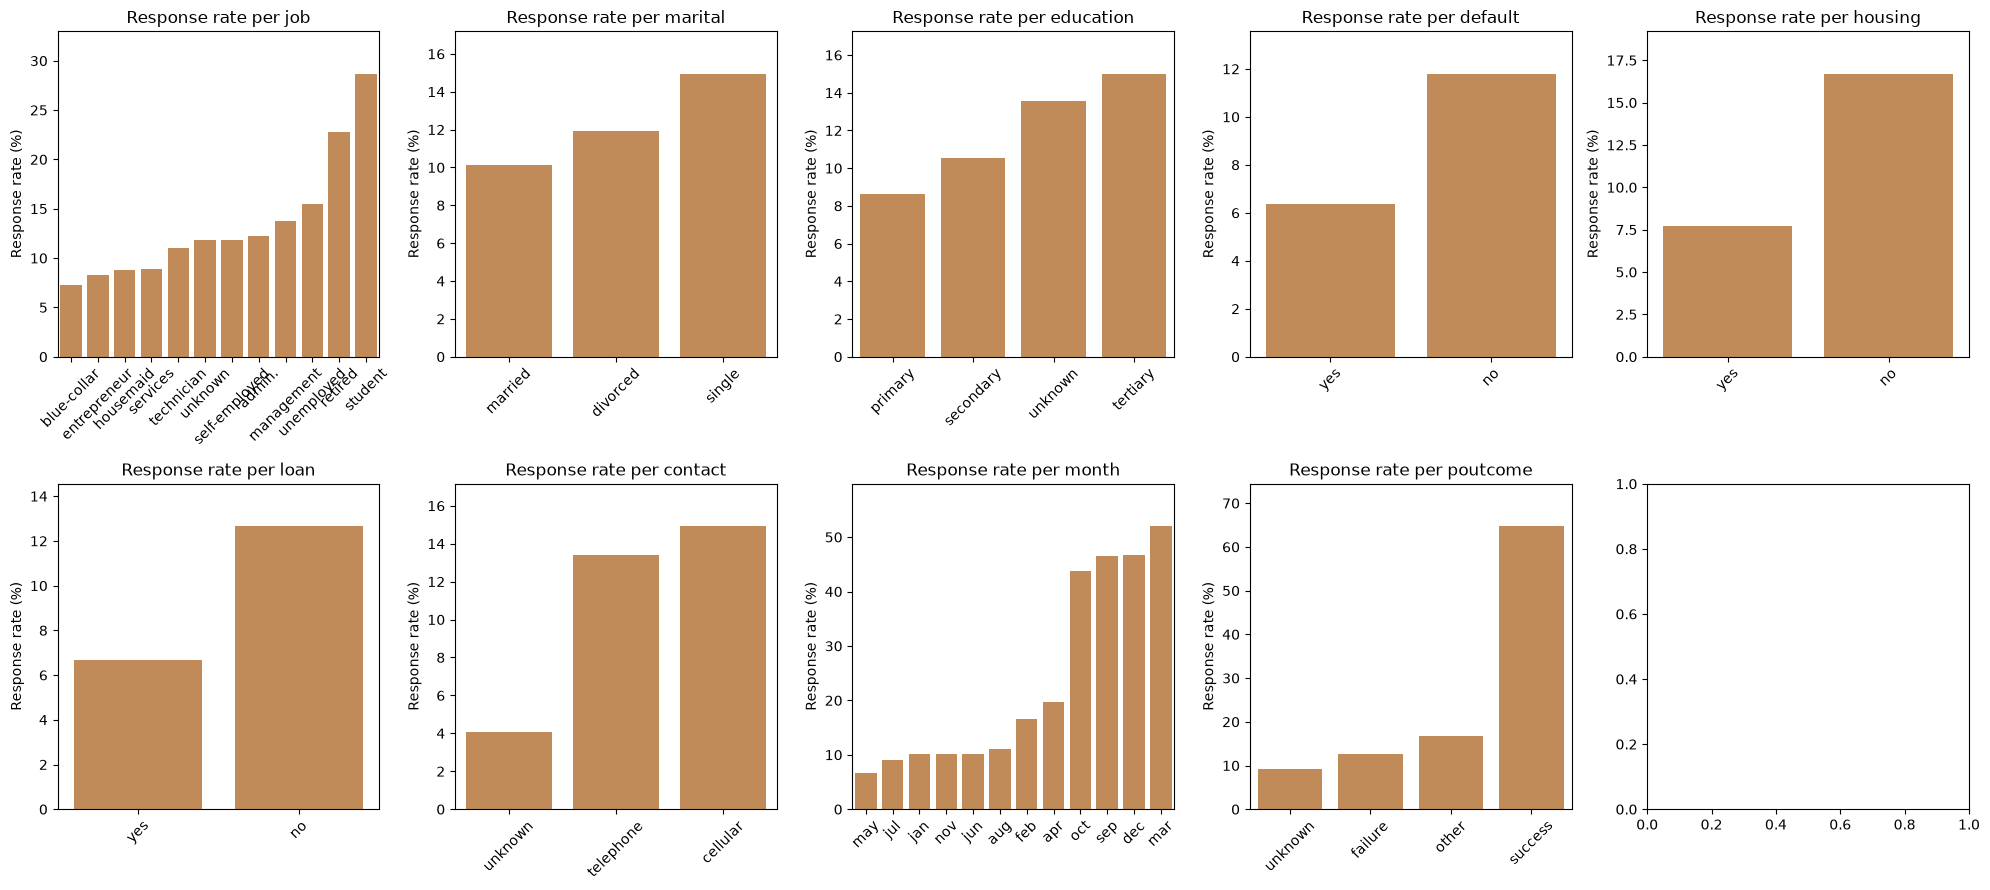

In [5]:
target_summary = df_clean["y"].value_counts().reindex(["no", "yes"], fill_value=0).to_frame("contacts")
target_summary["share_pct"] = target_summary["contacts"].div(len(df_clean)).mul(100)
response_rate_overall = df_clean["y"].eq("yes").mean() * 100
print(f"Response rate keseluruhan: {response_rate_overall:.2f}%")
display(target_summary.round(2))

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df_clean, x="y", order=["no", "yes"], color="#3f7f8c", ax=ax)
ax.set(title="Distribusi Target Berlangganan Deposito", xlabel="Berlangganan (y)", ylabel="Jumlah nasabah")
for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}")
plt.tight_layout()
plt.show()

numeric_fig, numeric_axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, column in zip(numeric_axes.flat, NUMERIC_COLUMNS):
    sns.histplot(data=df_clean, x=column, bins=35, color="#4c8c72", ax=ax)
    ax.set_title(f"Distribusi {column}")
    ax.set_ylabel("Jumlah")
for ax in numeric_axes.flat[len(NUMERIC_COLUMNS):]:
    ax.set_visible(False)
numeric_fig.tight_layout()
plt.show()

numeric_target_summary = df_clean.groupby("y")[NUMERIC_COLUMNS].agg(["median", "mean"]).T
print("Ringkasan fitur numerik per target:")
display(numeric_target_summary.round(2))

numeric_target_fig, numeric_target_axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, column in zip(numeric_target_axes.flat, NUMERIC_COLUMNS):
    sns.boxplot(
        data=df_clean, x="y", y=column, order=["no", "yes"],
        showfliers=False, color="#74a895", ax=ax,
    )
    ax.set_title(f"{column} menurut target")
    ax.set_xlabel("Berlangganan (y)")
for ax in numeric_target_axes.flat[len(NUMERIC_COLUMNS):]:
    ax.set_visible(False)
numeric_target_fig.tight_layout()
plt.show()

response_rate_tables = []
for column in CATEGORICAL_COLUMNS:
    segment_summary = (
        df_clean.groupby(column, dropna=False, observed=True)
        .agg(
            contacts=("y", "size"),
            subscriptions=("y", lambda values: values.eq("yes").sum()),
        )
        .reset_index()
        .rename(columns={column: "segment"})
    )
    segment_summary.insert(0, "feature", column)
    segment_summary["response_rate_pct"] = (
        segment_summary["subscriptions"].div(segment_summary["contacts"]).mul(100)
    )
    response_rate_tables.append(segment_summary)

response_rates = pd.concat(response_rate_tables, ignore_index=True)
response_rates = response_rates.sort_values(
    ["feature", "response_rate_pct"], ascending=[True, False]
).reset_index(drop=True)
display(response_rates.round({"response_rate_pct": 2}))

rate_fig, rate_axes = plt.subplots(2, 5, figsize=(20, 9))
for ax, column in zip(rate_axes.flat, CATEGORICAL_COLUMNS):
    plot_data = response_rates[response_rates["feature"].eq(column)].sort_values("response_rate_pct")
    sns.barplot(data=plot_data, x="segment", y="response_rate_pct", color="#d18b47", ax=ax)
    ax.set_title(f"Response rate per {column}")
    ax.set_xlabel("")
    ax.set_ylabel("Response rate (%)")
    ax.tick_params(axis="x", rotation=45)
    ax.set_ylim(0, max(10, plot_data["response_rate_pct"].max() * 1.15))
rate_fig.tight_layout()
plt.show()

## Temuan bisnis

Berdasarkan 45.211 observasi, sebanyak 5.289 nasabah berlangganan deposito (response rate **11,70%**); kelas target tidak seimbang.

- Riwayat kampanye sebelumnya yang berstatus `success` memiliki response rate **64,73%** (978 dari 1.511). Segmen ini layak diprioritaskan untuk pengujian tindak lanjut, dengan evaluasi biaya dan kapasitas.
- Response rate tertinggi menurut pekerjaan ada pada `student` (**28,68%**, n=938) dan `retired` (**22,79%**, n=2.264). Keduanya merupakan hipotesis segmen, bukan bukti bahwa pekerjaan menyebabkan konversi.
- Bulan `mar` mencatat **51,99%** (n=477), sedangkan `may` **6,72%** (n=13.766). Perbedaan besar ini perlu diuji kembali dengan mempertimbangkan volume, periode, dan komposisi calon nasabah.
- Response rate pada kontak `cellular` adalah **14,92%**, dibandingkan kategori `unknown` **4,07%**. Pencatatan kanal kontak yang lebih baik dapat diuji sebagai langkah operasional.
- Nasabah tanpa pinjaman perumahan memiliki response rate **16,70%**, dibandingkan **7,70%** pada nasabah dengan pinjaman perumahan.
- Median `duration` adalah **426 detik** pada kelas `yes` dan **164 detik** pada kelas `no`. Durasi baru diketahui setelah panggilan, jadi fitur ini tidak boleh dipakai untuk prediksi sebelum panggilan; Modul 3 mengecualikannya untuk mencegah data leakage.

Semua angka di atas bersifat deskriptif dari dataset kampanye di Portugal. Perbedaan response rate tidak membuktikan hubungan sebab-akibat; periksa ukuran segmen dan validasi dengan eksperimen sebelum mengubah strategi kampanye.

In [6]:
from src.data_processing import save_clean

save_clean(df_clean, CLEAN_PATH)
saved_df = pd.read_csv(CLEAN_PATH)
assert len(saved_df) == len(df_clean)
assert saved_df.columns.tolist() == EXPECTED_COLUMNS
print(f"Baris: {len(saved_df):,} | Kolom: {len(saved_df.columns)}")

Dataset tersimpan dan tervalidasi: bank_campaign_clean.csv
Baris: 45,211 | Kolom: 17


Baris: 45,211 | Kolom: 17
